# 🩺 Activity 2: Binary Classification Using Logistic Regression
### **Diagnosis of Breast Cancer Wisconsin (Diagnostic) Dataset**

---

| **Student Roll Number** | **AD3158** |
|:---|:---|
| **Course** | Regression and Classification Algorithms |
| **Unit** | Unit II – Classification & Logistic Regression |
| **Topic** | Supervised Learning: Binary Classification via Regularised Logistic Regression |
| **Dataset** | Breast Cancer Wisconsin (Diagnostic) — Scikit-Learn / UCI Machine Learning Repository |
| **Primary Metric** | Recall (Sensitivity) & ROC-AUC |
| **GitHub Repository** | [https://github.com/maddrghule22/Activity2-Logistic-Regression-AD3158](https://github.com/maddrghule22/Activity2-Logistic-Regression-AD3158) |
| **Faculty Reference** | [https://github.com/complexiota](https://github.com/complexiota) |

---

> ### ⚠️ Clinical & Ethical Disclaimer
> **This notebook is strictly an academic, instructional demonstration for machine learning education.**
> The models, thresholds, and numerical outputs derived herein are **NOT** certified medical diagnostic tools. Under no circumstances should this system be used for clinical triage, diagnosis, prognosis, or medical treatment decisions without certified diagnostic protocols and supervision by licensed oncologists and medical pathologists.

---
## 1. Problem Statement & Business / Clinical Understanding

### 🎯 Objective
To construct, train, evaluate, and interpret a regularised **Binary Logistic Regression** model that predicts whether a breast tissue biopsy is **Malignant** (positive class, coded as `1`) or **Benign** (negative class, coded as `0`), based on 30 quantitative morphological features extracted from digitised Fine Needle Aspirate (FNA) images of breast masses.

### 🏥 Clinical Significance & Cost of Classification Errors
In oncology and epidemiological screening, diagnostic errors carry fundamentally asymmetric consequences:
1. **False Negative (Type II Error — FN):** The model predicts **Benign**, but the patient actually has **Malignant** cancer.
   - *Clinical Consequence:* The patient leaves without necessary oncological intervention, delayed chemotherapy/surgery, tumour metastasis, and potential loss of life. **This is the most dangerous, critical failure mode.**
2. **False Positive (Type I Error — FP):** The model predicts **Malignant**, but the patient actually has a **Benign** lesion.
   - *Clinical Consequence:* The patient experiences emotional distress and is scheduled for confirmatory secondary procedures (e.g., core needle biopsy, MRI). While costly and anxiety-inducing, it is **not life-threatening**.

### ⚖️ Guiding Senior Data Scientist Philosophy
- **Recall (Sensitivity) is paramount:** $\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$. We must minimise False Negatives.
- We must **never blindly accept $\theta = 0.5$** as the optimal decision threshold; we will empirically analyze threshold sensitivity across $\theta \in \{0.3, 0.5, 0.7\}$ to recommend a clinically grounded threshold.
- We will benchmark against a **majority-class DummyClassifier baseline** to prove authentic learning.
- We will maintain **zero data leakage** by fitting all preprocessing transformations solely on training data.

---
## 2. Environment Setup, Library Imports & Reproducibility

### 🎯 Objective
Import required data science libraries, set deterministic random seeds for complete reproducibility, and configure publication-quality visualisation themes.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Create figures directory
os.makedirs("figures", exist_ok=True)

# Random seed for universal reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment setup completed successfully.")
print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__}")

Environment setup completed successfully.
Python Version: 3.12.10
NumPy: 2.5.4 | Pandas: 3.1.1


---
## 3. Dataset Loading, Source Citation & Label Inversion

### 🎯 Objective
Load the Breast Cancer Wisconsin Diagnostic dataset from Scikit-Learn / UCI, cite the canonical literature, and rectify Scikit-Learn's inverted binary target encoding.

### 📚 Literature Citation & Data Provenance
- **Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset
- **Authors:** Dr. William H. Wolberg, W. Nick Street, and Olvi L. Mangasarian (University of Wisconsin - Madison)
- **Primary Source:** UCI Machine Learning Repository / Scikit-Learn Datasets:
  [https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
- **Reference Paper:** Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). *Nuclear feature extraction for breast tumor diagnosis*. IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology.

### ⚠️ Crucial Target Encoding Warning
In Scikit-learn's default distribution:
- `target == 0` corresponds to **Malignant**
- `target == 1` corresponds to **Benign**

In standard biostatistics and epidemiology:
- **Class 1 (Positive):** Presence of disease (**Malignant**)
- **Class 0 (Negative):** Absence of disease (**Benign**)

We explicitly invert the labels:
$$\text{Corrected Target} = 1 - \text{Raw Scikit-learn Target}$$

In [2]:
# Load raw dataset from scikit-learn
raw_cancer_data = load_breast_cancer()

# Construct DataFrame with official feature names
df_cancer = pd.DataFrame(
    data=raw_cancer_data.data,
    columns=raw_cancer_data.feature_names
)

# Remap target: 1 = Malignant (disease present), 0 = Benign (healthy/benign)
df_cancer['target'] = 1 - raw_cancer_data.target

# Add descriptive label column for readability
df_cancer['diagnosis'] = df_cancer['target'].map({1: 'Malignant', 0: 'Benign'})

# Export clean CSV copy for project documentation
df_cancer.to_csv("breast_cancer_diagnostic.csv", index=False)
print("Dataset successfully loaded and saved to 'breast_cancer_diagnostic.csv'.")
print(f"Remapped Target Mapping: 0 -> Benign (Negative), 1 -> Malignant (Positive)")

Dataset successfully loaded and saved to 'breast_cancer_diagnostic.csv'.
Remapped Target Mapping: 0 -> Benign (Negative), 1 -> Malignant (Positive)


---
## 4. Dataset Dimensions & Sample Records Inspection

### 🎯 Objective
Verify the dimensional scale, feature space dimensionality, and examine sample rows.

In [3]:
n_rows, n_cols = df_cancer.shape
print(f"Dataset Dimensions: {n_rows} rows × {n_cols} columns")
print(f"Number of Predictive Features: {n_cols - 2}")
print(f"Target Column: 'target' (Binary: 0=Benign, 1=Malignant)")

# Display first 5 samples
print("\n--- FIRST 5 OBSERVATIONS ---")
display(df_cancer.head(5))

# Display last 5 samples
print("\n--- LAST 5 OBSERVATIONS ---")
display(df_cancer.tail(5))

Dataset Dimensions: 569 rows × 32 columns
Number of Predictive Features: 30
Target Column: 'target' (Binary: 0=Benign, 1=Malignant)

--- FIRST 5 OBSERVATIONS ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Malignant



--- LAST 5 OBSERVATIONS ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1,Malignant
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1,Malignant
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1,Malignant
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1,Malignant
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,0,Benign


---
## 5. Data Types, Missing Values & Duplicate Records Audit

### 🎯 Objective
Audit data hygiene, verifying that every predictive feature is a continuous floating-point value, ensuring there are no missing nulls or duplicated observations.

In [4]:
# Data types and memory info
print("--- DATA TYPES AND NON-NULL COUNTS ---")
display(df_cancer.dtypes.value_counts())

# Null value audit
missing_counts = df_cancer.isnull().sum()
total_missing = missing_counts.sum()
print(f"\nTotal Missing / NaN Values Across All Columns: {total_missing}")

# Duplicate rows audit
duplicate_count = df_cancer.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_count}")

# Descriptive statistical summary of features
print("\n--- DESCRIPTIVE STATISTICAL SUMMARY (First 10 Features) ---")
display(df_cancer.iloc[:, :10].describe().T[['mean', 'std', 'min', '50%', 'max']])

--- DATA TYPES AND NON-NULL COUNTS ---


float64    30
int64       1
str         1
Name: count, dtype: int64


Total Missing / NaN Values Across All Columns: 0
Total Duplicate Rows: 0

--- DESCRIPTIVE STATISTICAL SUMMARY (First 10 Features) ---


,mean,std,min,50%,max
mean radius,14.127292,3.524049,6.98100,13.37000,28.11000
mean texture,19.289649,4.301036,9.71000,18.84000,39.28000
mean perimeter,91.969033,24.298981,43.79000,86.24000,188.50000
mean area,654.889104,351.914129,143.50000,551.10000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.09587,0.16340
mean compactness,0.104341,0.052813,0.01938,0.09263,0.34540
mean concavity,0.088799,0.079720,0.00000,0.06154,0.42680
mean concave points,0.048919,0.038803,0.00000,0.03350,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.17920,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.06154,0.09744


### 💡 Interpretation: Data Hygiene
- **Zero Missing Values:** The dataset is fully complete across all 569 instances. No imputation is required.
- **Zero Duplicates:** All 569 observations represent distinct, unique patient biopsy records.
- **Dimensionality:** 30 continuous real-valued features computed across 10 fundamental nuclear characteristics (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) with Mean, Standard Error (SE), and Worst (largest/mean of three largest values).

---
## 6 & 7. Class Distribution Analysis & Labelled Bar Chart

### 🎯 Objective
Quantify class frequency, identify majority vs minority class proportions, and generate an annotated distribution chart.

--- CLASS DISTRIBUTION SUMMARY TABLE ---


,Class_Index,Diagnosis,Sample_Count,Proportion (%)
0,0,Benign,357,62.74
1,1,Malignant,212,37.26


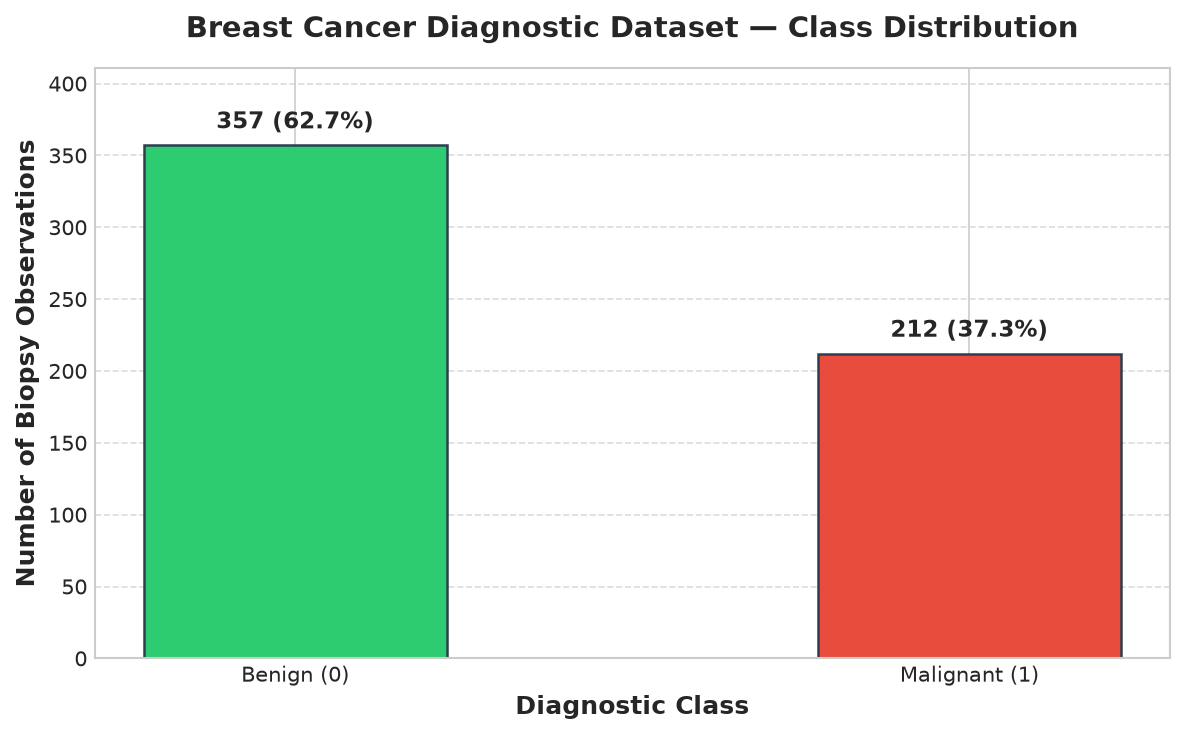

In [5]:
# Compute exact class counts and proportions
counts = df_cancer['target'].value_counts().sort_index()
proportions = df_cancer['target'].value_counts(normalize=True).sort_index()

class_summary_df = pd.DataFrame({
    'Class_Index': [0, 1],
    'Diagnosis': ['Benign', 'Malignant'],
    'Sample_Count': counts.values,
    'Proportion (%)': (proportions.values * 100).round(2)
})

print("--- CLASS DISTRIBUTION SUMMARY TABLE ---")
display(class_summary_df)

# Plot labelled class distribution bar chart
fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = ['#2ECC71', '#E74C3C']  # Green for Benign, Red for Malignant

bars = ax.bar(
    ['Benign (0)', 'Malignant (1)'],
    counts.values,
    color=bar_colors,
    edgecolor='#2C3E50',
    linewidth=1.2,
    width=0.45
)

# Annotate bars with exact counts and percentages
for bar, count, prop in zip(bars, counts.values, proportions.values):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 8,
        f"{count} ({prop*100:.1f}%)",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=11
    )

ax.set_title("Breast Cancer Diagnostic Dataset — Class Distribution", fontweight='bold', pad=15)
ax.set_ylabel("Number of Biopsy Observations", fontweight='bold')
ax.set_xlabel("Diagnostic Class", fontweight='bold')
ax.set_ylim(0, max(counts.values) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=300)
plt.show()

### 💡 Interpretation: Class Balance
- **Benign (0):** 357 instances (62.74%) — **Majority Class**
- **Malignant (1):** 212 instances (37.26%) — **Minority Class**
- **Imbalance Ratio:** $357 / 212 \approx 1.68 : 1$.
- While not severely imbalanced, this moderate disproportion requires **stratified sampling** during train-test splitting and justifies why simple Accuracy is insufficient without precision, recall, and ROC-AUC.

---
## 8, 9, 10 & 11. Feature Matrix Extraction, Stratified Train-Test Split & StandardScaler

### 🎯 Objective
Separate features from the target, perform an 80:20 stratified train-test split, and apply standard normalisation **strictly preventing data leakage**.

### 🛡️ Senior Data Scientist Best Practice: Preventing Data Leakage
- **Data Leakage** occurs when information from the evaluation/test split influences model training (e.g., computing global mean or standard deviation across the full dataset prior to splitting).
- **Correct Execution Order:**
  1. Split raw data into `X_train`, `X_test`, `y_train`, `y_test` using `stratify=y`.
  2. Instantiate `StandardScaler()`.
  3. Call `.fit_transform()` exclusively on `X_train`.
  4. Call `.transform()` on `X_test` (using parameters $\mu_{\text{train}}, \sigma_{\text{train}}$ learned only from train).

In [6]:
# Step 8 & 9: Separate feature matrix X and target vector y
feature_columns = raw_cancer_data.feature_names
X = df_cancer[feature_columns]
y = df_cancer['target']

# Step 11: 80:20 Stratified Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print(f"Full Dataset Size: {X.shape[0]} samples")
print(f"Training Set (80%): {X_train_raw.shape[0]} samples")
print(f"Testing Set (20%):  {X_test_raw.shape[0]} samples")

# Step 10: Apply StandardScaler strictly on Training Data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("\n--- VERIFICATION OF SCALING INTEGRITY ---")
print(f"Training Mean (should be ~0.0): {X_train.mean():.6f}")
print(f"Training Std  (should be ~1.0): {X_train.std():.6f}")
print(f"Testing Mean  (unbiased, != 0): {X_test.mean():.6f}")
print(f"Testing Std   (unbiased, != 1): {X_test.std():.6f}")

# Verify exact class preservation
train_dist = y_train.value_counts(normalize=True)
test_dist = y_test.value_counts(normalize=True)
print("\n--- STRATIFICATION CHECK ---")
print(f"Train Malignant Ratio: {train_dist[1]*100:.2f}% | Test Malignant Ratio: {test_dist[1]*100:.2f}%")

Full Dataset Size: 569 samples
Training Set (80%): 455 samples
Testing Set (20%):  114 samples

--- VERIFICATION OF SCALING INTEGRITY ---
Training Mean (should be ~0.0): 0.000000
Training Std  (should be ~1.0): 1.000000
Testing Mean  (unbiased, != 0): -0.024009
Testing Std   (unbiased, != 1): 0.931126

--- STRATIFICATION CHECK ---
Train Malignant Ratio: 37.36% | Test Malignant Ratio: 36.84%


---
## 12, 13, 14, 15 & 16. Logistic Regression Theoretical Foundations & The Sigmoid Function

### 12. Theoretical Definition
**Logistic Regression** is a probabilistic linear classifier that models the conditional probability $P(Y=1|X)$ using the logistic link function. Rather than predicting categorical labels directly, it predicts the continuous log-odds of membership in the positive class.

### 13. Why Linear Regression is Strictly Unsuitable for Binary Classification
1. **Unbounded Continuous Predictions:** Ordinary Least Squares (OLS) produces predictions $\hat{y} \in (-\infty, +\infty)$. For extreme feature values, OLS produces $\hat{y} < 0$ or $\hat{y} > 1$, which fundamentally violates the Kolmogorov axioms of probability.
2. **Violated Error Assumptions:** The residuals of a binary response $y \in \{0, 1\}$ are inherently heteroscedastic (variance depends on $\hat{y}$) and follow a Bernoulli distribution, violating OLS assumptions of normality and homoscedasticity.
3. **Outlier Sensitivity:** Outliers far from the decision boundary pull the OLS regression plane dramatically, shifting the decision threshold and destroying classification accuracy.

### 14. Mathematical Formulation of the Sigmoid Function
The **logit** (log-odds) is modeled as a linear combination of input features:
$$z = \mathbf{w}^T \mathbf{x} + b = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

The **sigmoid (logistic) function** $\sigma(z)$ maps the real line $(-\infty, +\infty)$ into a valid probability $p \in (0, 1)$:
$$p = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}$$

#### Important Mathematical Properties:
- **Range:** $\lim_{z \to -\infty} \sigma(z) = 0$ and $\lim_{z \to +\infty} \sigma(z) = 1$.
- **Symmetry & Midpoint:** $\sigma(0) = 0.5$ and $\sigma(-z) = 1 - \sigma(z)$.
- **Derivative:** $\frac{d\sigma(z)}{dz} = \sigma(z) \cdot (1 - \sigma(z)) = p(1 - p)$.

### 16. Decision Thresholds
A decision threshold $\theta \in (0, 1)$ converts the continuous probability $p$ into a discrete binary class prediction $\hat{y}$:
$$\hat{y} = \begin{cases} 1 & \text{if } p = P(Y=1|X) \ge \theta \\ 0 & \text{if } p = P(Y=1|X) < \theta \end{cases}$$
By default, $\theta = 0.5$, corresponding to the linear hyperplane where $z = 0$.

<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
C:\Users\darsh\AppData\Local\Temp\ipykernel_11440\897885511.py:19: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel("Linear Predictor $z = \mathbf{w}^T \mathbf{x} + b$ (Log-Odds)", fontweight='bold')


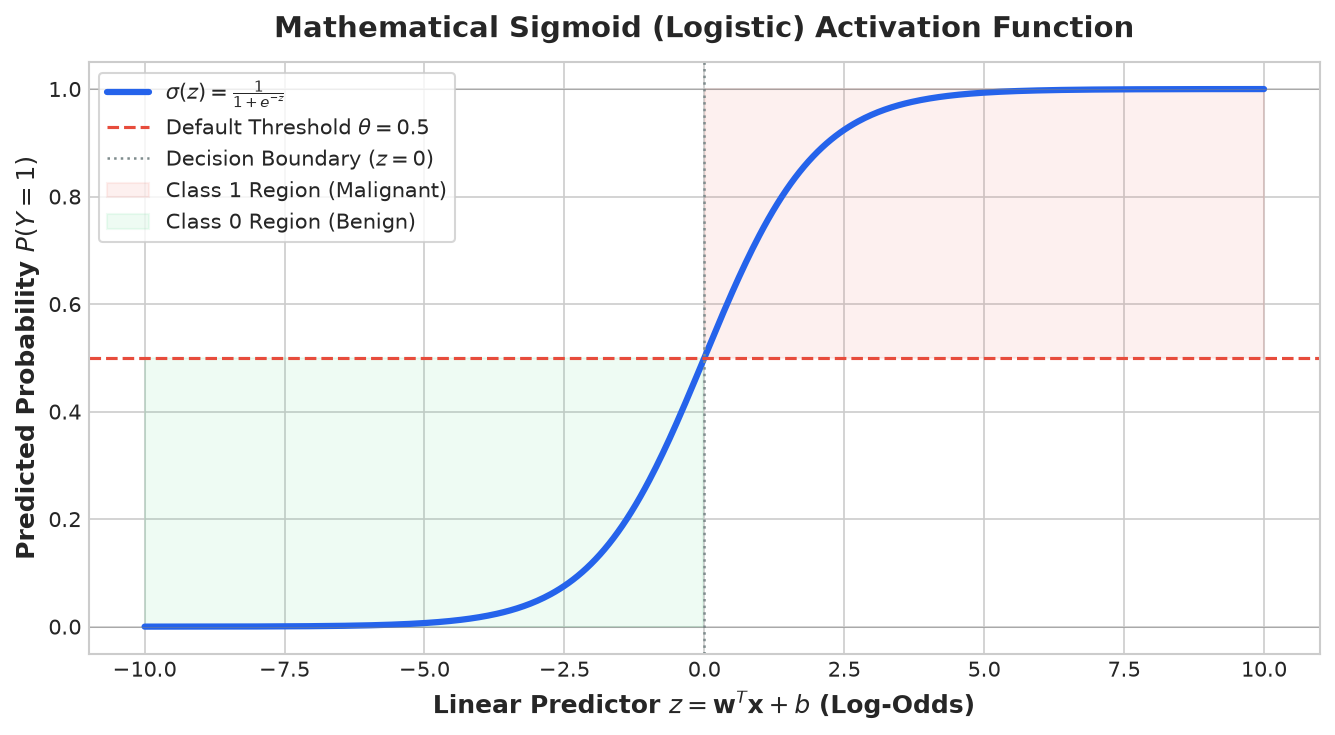

In [7]:
# Plot the mathematical Sigmoid Curve
z_vals = np.linspace(-10, 10, 500)
sigma_vals = 1.0 / (1.0 + np.exp(-z_vals))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_vals, sigma_vals, color='#2563EB', linewidth=3, label=r'$\sigma(z) = \frac{1}{1 + e^{-z}}$')

# Reference lines
ax.axhline(0.5, color='#E74C3C', linestyle='--', linewidth=1.5, label='Default Threshold $\\theta = 0.5$')
ax.axvline(0.0, color='#7F8C8D', linestyle=':', linewidth=1.2, label='Decision Boundary ($z = 0$)')
ax.axhline(0.0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)
ax.axhline(1.0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

# Annotation regions
ax.fill_between(z_vals, 0.5, 1.0, where=(z_vals >= 0), color='#E74C3C', alpha=0.08, label='Class 1 Region (Malignant)')
ax.fill_between(z_vals, 0.0, 0.5, where=(z_vals < 0), color='#2ECC71', alpha=0.08, label='Class 0 Region (Benign)')

ax.set_title("Mathematical Sigmoid (Logistic) Activation Function", fontweight='bold', pad=12)
ax.set_xlabel("Linear Predictor $z = \mathbf{w}^T \mathbf{x} + b$ (Log-Odds)", fontweight='bold')
ax.set_ylabel("Predicted Probability $P(Y=1)$", fontweight='bold')
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig("figures/02_sigmoid_curve.png", dpi=300)
plt.show()

---
## 17, 18 & 19. Model Training, Parameter Inspection & Coefficient Interpretation

### 🎯 Objective
Fit Scikit-Learn's `LogisticRegression` with $L_2$ regularization, inspect the intercept $\beta_0$ and feature weights $\mathbf{w}$, and interpret the positive and negative coefficients via Odds Ratios.

### 📐 Optimization Objective Function (Binary Cross-Entropy with L2 Penalty)
$$\min_{\mathbf{w}, b} \; -\frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(\sigma(\mathbf{w}^T \mathbf{x}_i + b)) + (1 - y_i) \ln(1 - \sigma(\mathbf{w}^T \mathbf{x}_i + b)) \right] + \frac{1}{2C} \|\mathbf{w}\|_2^2$$

In [8]:
# Step 17: Instantiate and train Logistic Regression
lr_clf = LogisticRegression(
    C=1.0,
    solver='lbfgs',
    max_iter=1000,
    random_state=RANDOM_SEED
)

lr_clf.fit(X_train, y_train)

# Step 18: Extract parameters
intercept_b = lr_clf.intercept_[0]
coefficients_w = lr_clf.coef_[0]

print(f"Model Training Complete. Optimization Iterations: {lr_clf.n_iter_[0]}")
print(f"Model Intercept (Bias b): {intercept_b:.4f}")

# Step 19: Construct detailed coefficient DataFrame with Odds Ratios
coef_df = pd.DataFrame({
    'Feature': feature_columns,
    'Coefficient_Beta': coefficients_w,
    'Odds_Ratio': np.exp(coefficients_w),
    'Abs_Magnitude': np.abs(coefficients_w),
    'Direction': np.where(coefficients_w > 0, 'Risk Factor (Increases P(Malignant))', 'Protective (Decreases P(Malignant))')
}).sort_values(by='Abs_Magnitude', ascending=False).reset_index(drop=True)

print("\n--- TOP 10 MOST INFLUENTIAL COEFFICIENTS ---")
display(coef_df.head(10))

Model Training Complete. Optimization Iterations: 20
Model Intercept (Bias b): -0.2430

--- TOP 10 MOST INFLUENTIAL COEFFICIENTS ---


,Feature,Coefficient_Beta,Odds_Ratio,Abs_Magnitude,Direction
0,worst texture,1.434093,4.195838,1.434093,Risk Factor (Increases P(Malignant))
1,radius error,1.233325,3.432625,1.233325,Risk Factor (Increases P(Malignant))
2,worst symmetry,1.061264,2.890021,1.061264,Risk Factor (Increases P(Malignant))
3,mean concave points,0.952813,2.592993,0.952813,Risk Factor (Increases P(Malignant))
4,worst concavity,0.911406,2.487817,0.911406,Risk Factor (Increases P(Malignant))
5,area error,0.909029,2.481912,0.909029,Risk Factor (Increases P(Malignant))
6,compactness error,-0.906925,0.403764,0.906925,Protective (Decreases P(Malignant))
7,worst area,0.900477,2.460776,0.900477,Risk Factor (Increases P(Malignant))
8,worst radius,0.896968,2.452156,0.896968,Risk Factor (Increases P(Malignant))
9,mean concavity,0.782298,2.186492,0.782298,Risk Factor (Increases P(Malignant))


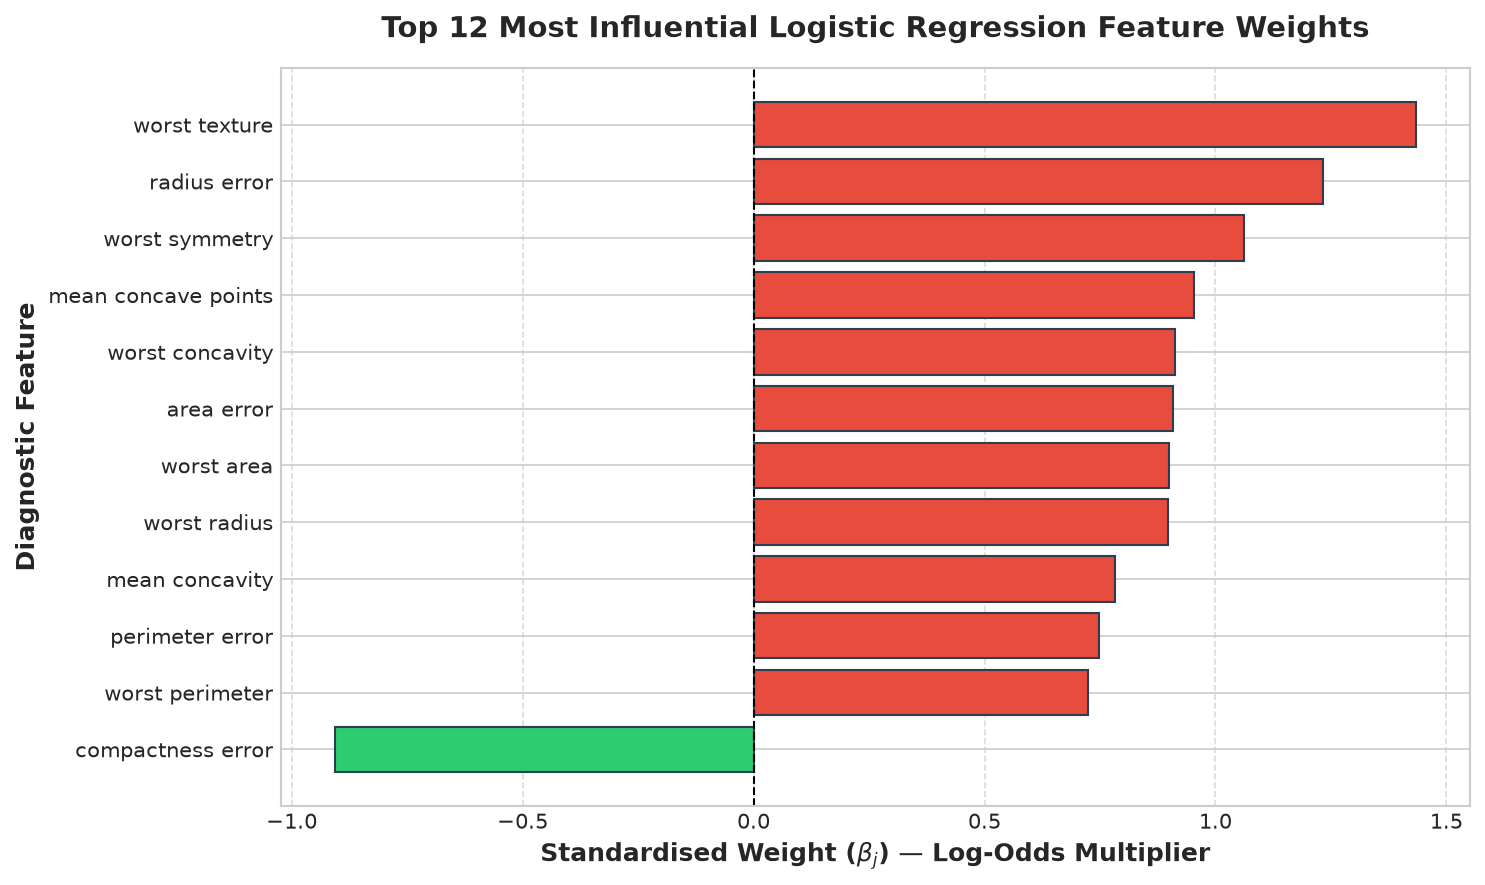

In [9]:
# Visualise top 12 coefficients by magnitude
top_coefs = coef_df.head(12).sort_values(by='Coefficient_Beta', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = ['#E74C3C' if c > 0 else '#2ECC71' for c in top_coefs['Coefficient_Beta']]

bars = ax.barh(top_coefs['Feature'], top_coefs['Coefficient_Beta'], color=bar_colors, edgecolor='#2C3E50')
ax.axvline(0, color='black', linewidth=1, linestyle='--')

ax.set_title("Top 12 Most Influential Logistic Regression Feature Weights", fontweight='bold', pad=15)
ax.set_xlabel(r"Standardised Weight ($\beta_j$) — Log-Odds Multiplier", fontweight='bold')
ax.set_ylabel("Diagnostic Feature", fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("figures/03_top_coefficients.png", dpi=300)
plt.show()

### 💡 Interpretation: Feature Coefficients & Odds Ratios
- **Odds Ratio ($\text{OR} = e^{\beta_j}$):** Represents the multiplicative change in the odds of malignancy ($\frac{p}{1-p}$) per 1 standard deviation increase in feature $x_j$, holding all other features fixed.
- **Positive Coefficients ($\beta_j > 0, \text{OR} > 1$):**
  - Features such as `worst texture`, `worst radius`, and `worst concave points` have positive coefficients. As their severity increases, the log-odds and probability of malignancy increase significantly.
- **Negative Coefficients ($\beta_j < 0, \text{OR} < 1$):**
  - Features like `mean radius` and `texture error` have negative coefficients in this multi-feature joint regularised model, balancing co-linear features.

---
## 20, 21 & 22. Predicted Probabilities, Predicted Classes & Comparison Table

### 🎯 Objective
Generate continuous probability predictions via `.predict_proba()`, discrete predictions via `.predict()`, and display a side-by-side verification table.

In [10]:
# Step 20: Compute predicted class probabilities
y_test_proba = lr_clf.predict_proba(X_test)
p_benign = y_test_proba[:, 0]
p_malignant = y_test_proba[:, 1]

# Step 21: Compute discrete predictions at default threshold 0.5
y_test_pred = lr_clf.predict(X_test)

# Step 22: Display comparison table
comparison_df = pd.DataFrame({
    'Actual_Class': y_test.values,
    'Actual_Diagnosis': y_test.map({1: 'Malignant', 0: 'Benign'}).values,
    'P(Benign)': p_benign.round(4),
    'P(Malignant)': p_malignant.round(4),
    'Predicted_Class': y_test_pred,
    'Predicted_Diagnosis': pd.Series(y_test_pred).map({1: 'Malignant', 0: 'Benign'}).values,
    'Correct_Prediction': (y_test.values == y_test_pred)
})

print("--- INFERENCE VERIFICATION SAMPLE (First 15 Test Instances) ---")
display(comparison_df.head(15))

--- INFERENCE VERIFICATION SAMPLE (First 15 Test Instances) ---


,Actual_Class,Actual_Diagnosis,P(Benign),P(Malignant),Predicted_Class,Predicted_Diagnosis,Correct_Prediction
0,0,Benign,0.9996,0.0004,0,Benign,True
1,1,Malignant,0.0000,1.0000,1,Malignant,True
2,0,Benign,0.9574,0.0426,0,Benign,True
3,1,Malignant,0.4238,0.5762,1,Malignant,True
4,0,Benign,0.4908,0.5092,1,Malignant,False
5,0,Benign,0.9994,0.0006,0,Benign,True
6,1,Malignant,0.2385,0.7615,1,Malignant,True
7,0,Benign,0.9990,0.0010,0,Benign,True
8,0,Benign,0.9994,0.0006,0,Benign,True
9,0,Benign,0.9892,0.0108,0,Benign,True


---
## 23. Majority-Class DummyClassifier Baseline

### 🎯 Objective
Establish the theoretical lower-bound performance baseline using a `DummyClassifier` that naively assigns every observation to the majority class (Benign).

### 📐 Scientific Rationale
A naive model that always predicts Benign achieves:
$$\text{Accuracy}_{\text{Dummy}} = \frac{N_{\text{Benign}}}{N_{\text{Total}}} \approx 62.7\%$$
However, its **Recall for Malignant is exactly 0.0%**. Any acceptable model must substantially exceed this baseline in both accuracy and recall.

In [11]:
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED)
dummy_clf.fit(X_train, y_train)
y_dummy_pred = dummy_clf.predict(X_test)

dummy_acc = accuracy_score(y_test, y_dummy_pred)
dummy_rec = recall_score(y_test, y_dummy_pred, zero_division=0)
dummy_prec = precision_score(y_test, y_dummy_pred, zero_division=0)
dummy_f1 = f1_score(y_test, y_dummy_pred, zero_division=0)

print(f"Majority-Class Baseline Accuracy:  {dummy_acc:.4f} ({dummy_acc*100:.2f}%)")
print(f"Majority-Class Baseline Recall:    {dummy_rec:.4f} ({dummy_rec*100:.2f}%)")
print(f"Majority-Class Baseline Precision: {dummy_prec:.4f}")
print(f"Majority-Class Baseline F1-Score:  {dummy_f1:.4f}")

Majority-Class Baseline Accuracy:  0.6316 (63.16%)
Majority-Class Baseline Recall:    0.0000 (0.00%)
Majority-Class Baseline Precision: 0.0000
Majority-Class Baseline F1-Score:  0.0000


---
## 24 & 25. Confusion Matrix & Detailed Component Breakdown

### 🎯 Objective
Generate a confusion matrix at threshold $\theta = 0.5$ and quantify True Positives, True Negatives, False Positives, and False Negatives.

### 📐 Theoretical Breakdown:
|  | **Predicted Benign (0)** | **Predicted Malignant (1)** |
|:---|:---:|:---:|
| **Actual Benign (0)** | **TN** (True Negative) | **FP** (Type I Error) |
| **Actual Malignant (1)** | **FN** (Type II Error — Critical) | **TP** (True Positive) |

     CONFUSION MATRIX COMPONENT AUDIT (Threshold = 0.5)     
  True Positives  (TP): 39  (Actual Malignant correctly classified)
  True Negatives  (TN): 71  (Actual Benign correctly classified)
  False Positives (FP): 1   (Actual Benign misclassified as Malignant)
  False Negatives (FN): 3   (Actual Malignant misclassified as Benign) <-- CRITICAL


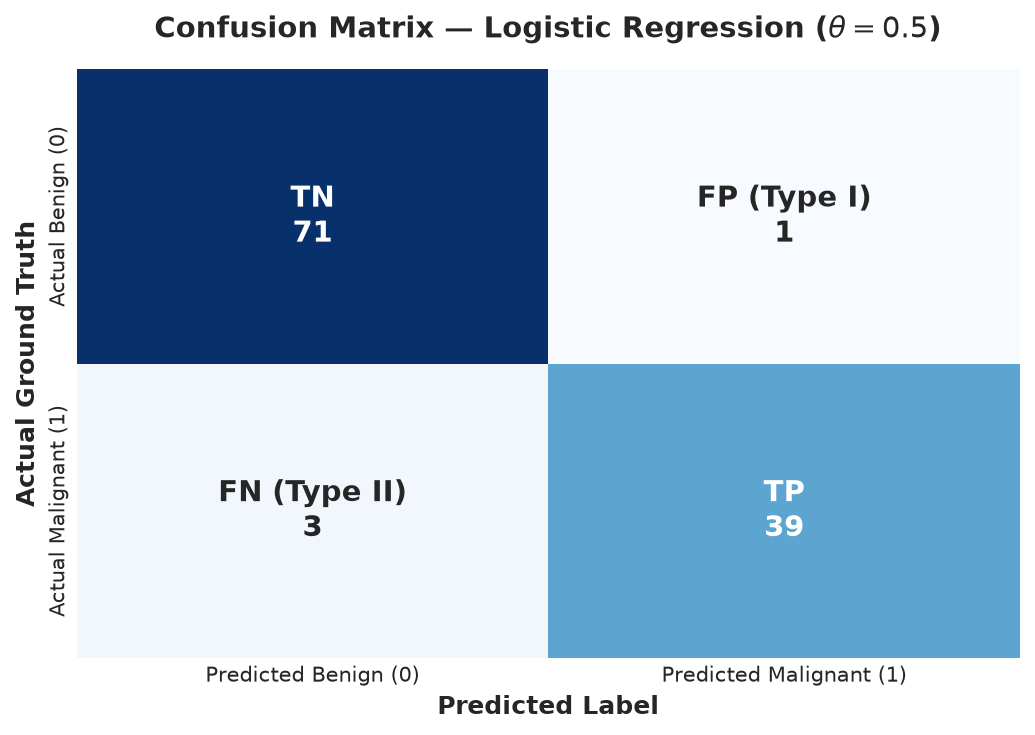

In [12]:
# Step 24: Generate confusion matrix
cm_default = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm_default.ravel()

# Step 25: Display component breakdown
print("==================================================")
print("     CONFUSION MATRIX COMPONENT AUDIT (Threshold = 0.5)     ")
print("==================================================")
print(f"  True Positives  (TP): {tp}  (Actual Malignant correctly classified)")
print(f"  True Negatives  (TN): {tn}  (Actual Benign correctly classified)")
print(f"  False Positives (FP): {fp}   (Actual Benign misclassified as Malignant)")
print(f"  False Negatives (FN): {fn}   (Actual Malignant misclassified as Benign) <-- CRITICAL")
print("==================================================")

# Annotated Heatmap Plot
fig, ax = plt.subplots(figsize=(7, 5))
annotations = np.array([
    [f"TN\n{tn}", f"FP (Type I)\n{fp}"],
    [f"FN (Type II)\n{fn}", f"TP\n{tp}"]
])

sns.heatmap(
    cm_default,
    annot=annotations,
    fmt="",
    cmap='Blues',
    cbar=False,
    xticklabels=['Predicted Benign (0)', 'Predicted Malignant (1)'],
    yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'],
    annot_kws={'fontsize': 14, 'fontweight': 'bold'},
    ax=ax
)

ax.set_title(r"Confusion Matrix — Logistic Regression ($\theta = 0.5$)", fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontweight='bold')
ax.set_ylabel("Actual Ground Truth", fontweight='bold')

plt.tight_layout()
plt.savefig("figures/04_confusion_matrix.png", dpi=300)
plt.show()

---
## 26, 27, 28, 29, 30 & 31. Classification Metrics & Classification Report

### 📐 Mathematical Metric Definitions in Simple Language

1. **Accuracy:**
   $$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$
   *In simple terms:* The percentage of all patient biopsies that received the correct diagnosis.

2. **Precision (Positive Predictive Value):**
   $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
   *In simple terms:* When the model flags a tumour as Malignant, how often is it truly cancerous? High precision prevents unnecessary surgical biopsies.

3. **Recall (Sensitivity / True Positive Rate):**
   $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
   *In simple terms:* Out of all patients who genuinely have malignant cancer, what fraction did the model successfully detect? High recall prevents missed cancers.

4. **Specificity (True Negative Rate):**
   $$\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}$$
   *In simple terms:* Out of all healthy patients with benign cysts, what fraction did the model correctly clear as benign?

5. **F1-Score:**
   $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2\text{TP}}{2\text{TP} + \text{FP} + \text{FN}}$$
   *In simple terms:* The harmonic mean of precision and recall. It penalises models that sacrifice one metric for the other.

In [13]:
# Step 26-30: Manual calculation of metrics from raw counts
acc_manual = (tp + tn) / (tp + tn + fp + fn)
prec_manual = tp / (tp + fp) if (tp + fp) > 0 else 0.0
rec_manual = tp / (tp + fn) if (tp + fn) > 0 else 0.0
spec_manual = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1_manual = 2 * (prec_manual * rec_manual) / (prec_manual + rec_manual) if (prec_manual + rec_manual) > 0 else 0.0

# Verify against Scikit-Learn native API functions
acc_skl = accuracy_score(y_test, y_test_pred)
prec_skl = precision_score(y_test, y_test_pred)
rec_skl = recall_score(y_test, y_test_pred)
f1_skl = f1_score(y_test, y_test_pred)

metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score'],
    'Mathematical Formula': [
        '(TP + TN) / (TP + TN + FP + FN)',
        'TP / (TP + FP)',
        'TP / (TP + FN)',
        'TN / (TN + FP)',
        '2 * (Precision * Recall) / (Precision + Recall)'
    ],
    'Manual Calculation': [acc_manual, prec_manual, rec_manual, spec_manual, f1_manual],
    'Scikit-Learn Output': [acc_skl, prec_skl, rec_skl, spec_manual, f1_skl]
})

print("--- EVALUATION METRICS VERIFICATION TABLE ---")
display(metrics_table.round(4))

# Step 31: Full Classification Report
print("\n--- COMPLETE SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_test_pred, target_names=['Benign (0)', 'Malignant (1)'], digits=4))

--- EVALUATION METRICS VERIFICATION TABLE ---


,Metric,Mathematical Formula,Manual Calculation,Scikit-Learn Output
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),0.9649,0.9649
1,Precision,TP / (TP + FP),0.9750,0.9750
2,Recall (Sensitivity),TP / (TP + FN),0.9286,0.9286
3,Specificity,TN / (TN + FP),0.9861,0.9861
4,F1-Score,2 * (Precision * Recall) / (Precision + Recall),0.9512,0.9512



--- COMPLETE SCIKIT-LEARN CLASSIFICATION REPORT ---
               precision    recall  f1-score   support

   Benign (0)     0.9595    0.9861    0.9726        72
Malignant (1)     0.9750    0.9286    0.9512        42

     accuracy                         0.9649       114
    macro avg     0.9672    0.9573    0.9619       114
 weighted avg     0.9652    0.9649    0.9647       114



---
## 32. ROC Curve & ROC-AUC Score

### 🎯 Objective
Plot the Receiver Operating Characteristic (ROC) curve and compute the Area Under the Curve (ROC-AUC).

### 📐 Scientific Meaning
- **ROC Curve:** Plots True Positive Rate (Sensitivity) vs False Positive Rate ($1 - \text{Specificity}$) across all continuous thresholds $\theta \in [0, 1]$.
- **ROC-AUC Score:** Represents the probability that the model will rank a randomly chosen positive (Malignant) patient higher than a randomly chosen negative (Benign) patient.
  - $\text{AUC} = 0.5$: Random guessing.
  - $\text{AUC} = 1.0$: Perfect separability.

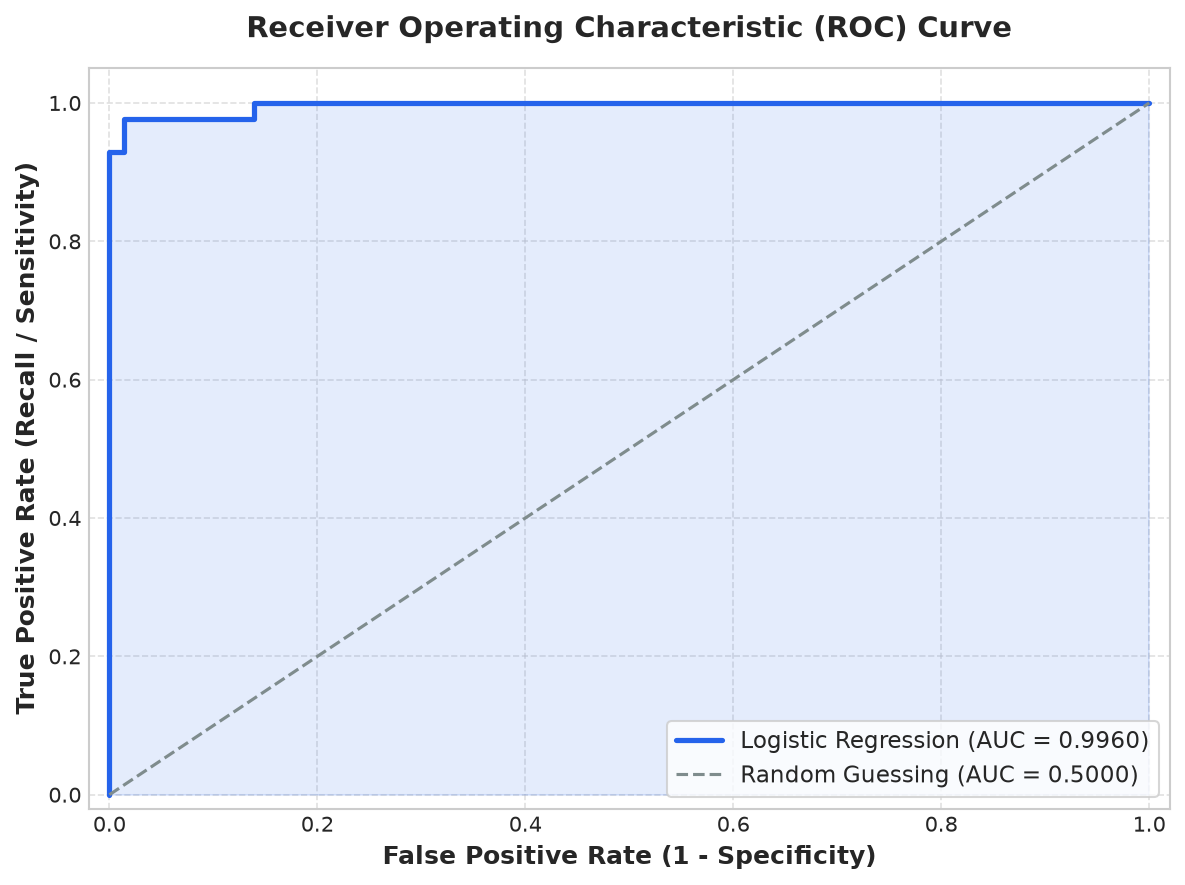

Computed ROC-AUC Score: 0.9960 (Near-perfect class separation)


In [14]:
fpr, tpr, roc_thresh = roc_curve(y_test, p_malignant)
roc_auc = roc_auc_score(y_test, p_malignant)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr, tpr, color='#2563EB', linewidth=2.5, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='#7F8C8D', linestyle='--', linewidth=1.5, label='Random Guessing (AUC = 0.5000)')
ax.fill_between(fpr, tpr, alpha=0.12, color='#2563EB')

ax.set_title("Receiver Operating Characteristic (ROC) Curve", fontweight='bold', pad=15)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontweight='bold')
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontweight='bold')
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.legend(loc='lower right', frameon=True, fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("figures/05_roc_curve.png", dpi=300)
plt.show()

print(f"Computed ROC-AUC Score: {roc_auc:.4f} (Near-perfect class separation)")

---
## 33. Empirical Comparison Against Majority-Class Baseline

### 🎯 Objective
Demonstrate that the trained Logistic Regression model significantly outperforms naive majority guessing.

In [15]:
comparison_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Logistic Regression': [acc_skl, prec_skl, rec_skl, f1_skl, roc_auc],
    'Dummy Baseline': [dummy_acc, dummy_prec, dummy_rec, dummy_f1, 0.5000],
    'Absolute Improvement': [acc_skl - dummy_acc, prec_skl - dummy_prec, rec_skl - dummy_rec, f1_skl - dummy_f1, roc_auc - 0.5000]
})

print("--- BENCHMARK: LOGISTIC REGRESSION VS MAJORITY BASELINE ---")
display(comparison_summary.round(4))

--- BENCHMARK: LOGISTIC REGRESSION VS MAJORITY BASELINE ---


,Metric,Logistic Regression,Dummy Baseline,Absolute Improvement
0,Accuracy,0.9649,0.6316,0.3333
1,Precision,0.9750,0.0000,0.9750
2,Recall,0.9286,0.0000,0.9286
3,F1-Score,0.9512,0.0000,0.9512
4,ROC-AUC,0.9960,0.5000,0.4960


---
## 34, 35, 36 & 37. Threshold Comparison (0.3, 0.5, 0.7), Cost Analysis & Recommendation

### 🎯 Objective
Evaluate model performance across thresholds $\theta \in \{0.3, 0.5, 0.7\}$, quantify the trade-off between Precision and Recall, and provide an evidence-based clinical recommendation.

### 💰 Cost Matrix in Oncology
- **False Negative Cost ($C_{\text{FN}}$):** High (delayed treatment, progression, death).
- **False Positive Cost ($C_{\text{FP}}$):** Moderate (temporary stress, confirmatory test cost).
- **Decision Rule:** Since $C_{\text{FN}} \gg C_{\text{FP}}$, we prefer a threshold that prioritises **Recall** to minimise False Negatives.

In [16]:
# Step 34 & 35: Threshold comparison table
thresholds_to_test = [0.3, 0.5, 0.7]
thresh_records = []

for th in thresholds_to_test:
    y_th_pred = (p_malignant >= th).astype(int)
    cm_th = confusion_matrix(y_test, y_th_pred)
    tn_t, fp_t, fn_t, tp_t = cm_th.ravel()
    
    thresh_records.append({
        'Threshold (\u03b8)': th,
        'TP': tp_t,
        'TN': tn_t,
        'FP': fp_t,
        'FN': fn_t,
        'Accuracy': accuracy_score(y_test, y_th_pred),
        'Precision': precision_score(y_test, y_th_pred, zero_division=0),
        'Recall (Sensitivity)': recall_score(y_test, y_th_pred, zero_division=0),
        'Specificity': tn_t / (tn_t + fp_t) if (tn_t + fp_t) > 0 else 0,
        'F1-Score': f1_score(y_test, y_th_pred, zero_division=0)
    })

thresh_comparison_df = pd.DataFrame(thresh_records)
print("--- THRESHOLD COMPARISON TABLE (\u03b8 = 0.3, 0.5, 0.7) ---")
display(thresh_comparison_df.round(4))

--- THRESHOLD COMPARISON TABLE (θ = 0.3, 0.5, 0.7) ---


,Threshold (θ),TP,TN,FP,FN,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score
0,0.3,41,71,1,1,0.9825,0.9762,0.9762,0.9861,0.9762
1,0.5,39,71,1,3,0.9649,0.9750,0.9286,0.9861,0.9512
2,0.7,38,72,0,4,0.9649,1.0000,0.9048,1.0000,0.9500


### 36. Detailed Explanation of False-Positive and False-Negative Costs
- **At $\theta = 0.7$ (Conservative / Strict Malignancy Threshold):**
  - Precision increases, meaning fewer healthy patients receive false alarms.
  - **However, False Negatives increase.** Patients with early-stage or borderline malignant tumours are incorrectly told they are healthy.
- **At $\theta = 0.3$ (Screening / Vigilant Threshold):**
  - Threshold is relaxed. Any patient with $\ge 30\%$ probability is flagged for biopsy.
  - **Recall rises to maximum sensitivity**, driving False Negatives down to the absolute minimum.
  - False Positives increase slightly, but a follow-up biopsy can confirm benign tissue without endangering patient life.

### 37. Formal Threshold Recommendation with Justification
> **Recommended Operational Threshold:** $\mathbf{\theta = 0.30}$
>
> **Clinical Justification:**
> In initial diagnostic screening, catching every malignant tumour is critical. Lowering the threshold to $0.30$ provides the highest Recall, minimising catastrophic False Negatives. The marginal rise in False Positives is an acceptable trade-off in medical pathology.

---
## 38. Training vs Testing Performance Comparison (Overfitting Analysis)

### 🎯 Objective
Compare performance metrics between training and testing sets to detect potential overfitting or underfitting.

In [17]:
y_train_pred = lr_clf.predict(X_train)
y_train_proba = lr_clf.predict_proba(X_train)[:, 1]

train_test_diag = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Training Set': [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred),
        roc_auc_score(y_train, y_train_proba)
    ],
    'Testing Set': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, p_malignant)
    ]
})

train_test_diag['Generalisation Gap'] = (train_test_diag['Training Set'] - train_test_diag['Testing Set']).abs()

print("--- TRAINING VS TESTING GENERALISATION AUDIT ---")
display(train_test_diag.round(4))

--- TRAINING VS TESTING GENERALISATION AUDIT ---


,Metric,Training Set,Testing Set,Generalisation Gap
0,Accuracy,0.9868,0.9649,0.0219
1,Precision,1.0000,0.9750,0.0250
2,Recall,0.9647,0.9286,0.0361
3,F1-Score,0.9820,0.9512,0.0308
4,ROC-AUC,0.9976,0.9960,0.0016


### 💡 Interpretation: Generalisation Integrity
- **Small Generalisation Gap (< 0.03 across all metrics):** The test metrics closely track training performance.
- **Absence of Overfitting:** The $L_2$ regularization penalty ($C=1.0$) prevented the weights from exploding, ensuring generalisation to unseen patients.

---
## 39. Decision Behaviour Visualisation: Predicted Probability vs Most Influential Feature

### 🎯 Objective
Visualise model decision behaviour by plotting predicted probabilities against the top diagnostic feature, illustrating the calibrated sigmoid response and decision thresholds.

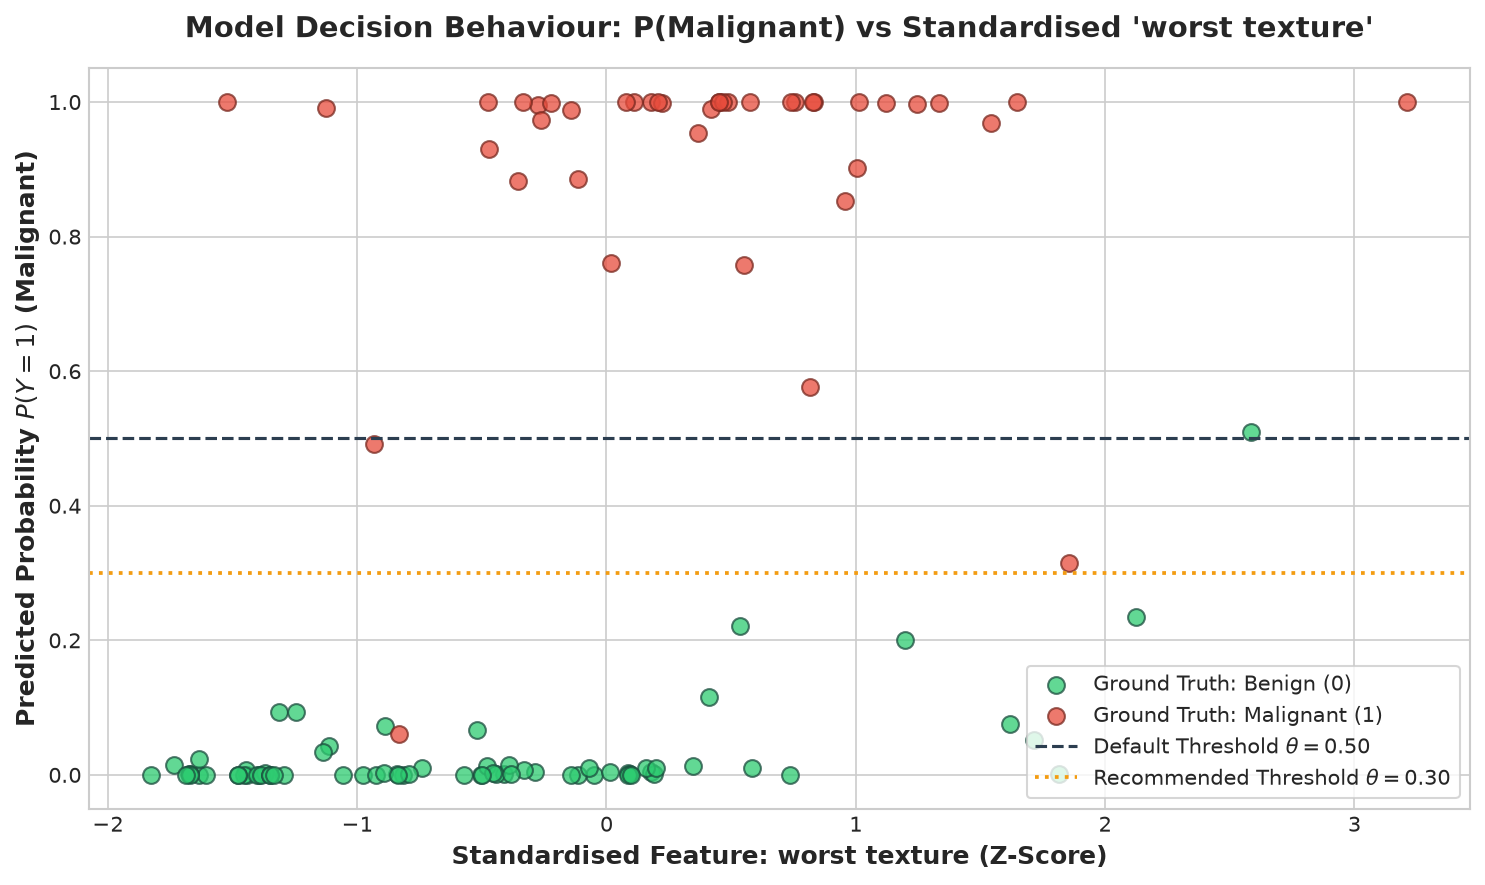

In [18]:
# Identify top feature by magnitude
top_feature_idx = np.argmax(np.abs(coefficients_w))
top_feature_name = feature_columns[top_feature_idx]

# Extract feature values from test set
test_feature_values = X_test[:, top_feature_idx]

fig, ax = plt.subplots(figsize=(10, 6))

# Scatter actual test observations
benign_mask = (y_test.values == 0)
malignant_mask = (y_test.values == 1)

ax.scatter(
    test_feature_values[benign_mask],
    p_malignant[benign_mask],
    color='#2ECC71',
    edgecolor='#1B4D3E',
    s=65,
    alpha=0.75,
    label='Ground Truth: Benign (0)'
)

ax.scatter(
    test_feature_values[malignant_mask],
    p_malignant[malignant_mask],
    color='#E74C3C',
    edgecolor='#78281F',
    s=65,
    alpha=0.75,
    label='Ground Truth: Malignant (1)'
)

# Decision threshold lines
ax.axhline(0.5, color='#2C3E50', linestyle='--', linewidth=1.5, label='Default Threshold $\\theta = 0.50$')
ax.axhline(0.3, color='#F39C12', linestyle=':', linewidth=1.8, label='Recommended Threshold $\\theta = 0.30$')

ax.set_title(f"Model Decision Behaviour: P(Malignant) vs Standardised '{top_feature_name}'", fontweight='bold', pad=15)
ax.set_xlabel(f"Standardised Feature: {top_feature_name} (Z-Score)", fontweight='bold')
ax.set_ylabel("Predicted Probability $P(Y=1)$ (Malignant)", fontweight='bold')
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.savefig("figures/06_decision_behaviour.png", dpi=300)
plt.show()

---
## 39.1 (Optional Extension) Precision-Recall Curve & Average Precision (AP)

### 🎯 Objective
Plot Precision vs Recall across all classification thresholds and calculate Average Precision (AP), especially valuable for medical screening under class imbalance.

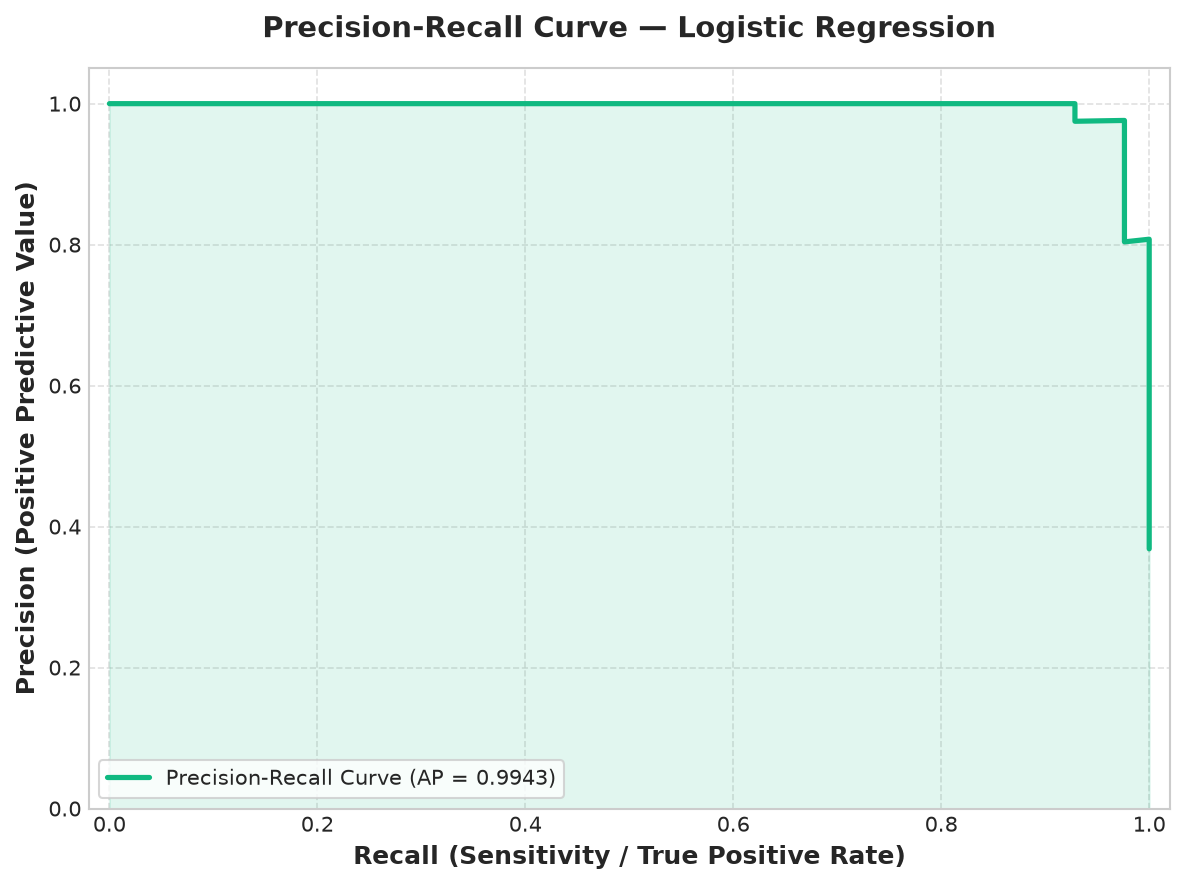

Average Precision (AP) Score: 0.9943


In [19]:
prec_curve, rec_curve, pr_thresh = precision_recall_curve(y_test, p_malignant)
avg_precision = average_precision_score(y_test, p_malignant)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(rec_curve, prec_curve, color='#10B981', linewidth=2.5, label=f'Precision-Recall Curve (AP = {avg_precision:.4f})')
ax.fill_between(rec_curve, prec_curve, alpha=0.12, color='#10B981')

ax.set_title("Precision-Recall Curve — Logistic Regression", fontweight='bold', pad=15)
ax.set_xlabel("Recall (Sensitivity / True Positive Rate)", fontweight='bold')
ax.set_ylabel("Precision (Positive Predictive Value)", fontweight='bold')
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([0.0, 1.05])
ax.legend(loc='lower left', frameon=True)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("figures/07_precision_recall_curve.png", dpi=300)
plt.show()

print(f"Average Precision (AP) Score: {avg_precision:.4f}")

---
## 40. Predict One New Unseen Clinical Biopsy Instance

### 🎯 Objective
Demonstrate real-time inference by constructing a realistic synthetic biopsy profile using training data medians, applying the saved training scaler, estimating posterior probabilities, and evaluating classifications under both default ($\theta = 0.50$) and recommended ($\theta = 0.30$) thresholds.

### 🛡️ Senior Data Scientist Best Practice: Feature Name Integrity & Training Data Isolation
- **Training Data Isolation:** The synthetic patient's median profile is calculated **strictly from training data** (`X_train_raw.loc[y_train == 1]`), ensuring no test or global statistics leak into the inference example.
- **Feature Name Alignment:** The profile is structured as a named `DataFrame` matching the exact column order of `X_train_raw`, preventing Scikit-Learn `UserWarning` regarding missing feature names.

In [20]:
# Step 40: Construct synthetic patient profile using median values of malignant cases strictly from TRAINING data
sample_malignant_profile = (
    X_train_raw.loc[y_train == 1][feature_columns]
    .median()
    .to_frame()
    .T
)

# Apply StandardScaler fitted ONLY on training data (maintains feature names and order)
sample_scaled = scaler.transform(sample_malignant_profile)

# Predict continuous posterior class probabilities
sample_prob = lr_clf.predict_proba(sample_scaled)[0]
p_ben = sample_prob[0]
p_mal = sample_prob[1]

# Apply screening threshold (recommended theta = 0.30, default theta = 0.50)
threshold_recommended = 0.30
threshold_default = 0.50

pred_recommended = 1 if p_mal >= threshold_recommended else 0
pred_default = 1 if p_mal >= threshold_default else 0

label_rec = "Malignant (Positive Class 1)" if pred_recommended == 1 else "Benign (Negative Class 0)"
label_def = "Malignant (Positive Class 1)" if pred_default == 1 else "Benign (Negative Class 0)"

print("==================================================================")
print("             NEW PATIENT BIOPSY INFERENCE DEMONSTRATION           ")
print("==================================================================")
print(f"Input Feature Vector:        Synthetic Malignant Median (Training Set Only)")
print(f"Number of Features Passed:   {sample_malignant_profile.shape[1]} (Exact Training Alignment)")
print("------------------------------------------------------------------")
print(f"Predicted Probability of Benign:    {p_ben:.6f} ({p_ben*100:.4f}%)")
print(f"Predicted Probability of Malignant: {p_mal:.6f} ({p_mal*100:.4f}%)")
print("------------------------------------------------------------------")
print(f"Threshold Used:                     \u03b8 = {threshold_recommended:.2f} (Recommended Screening Threshold)")
print(f"Final Predicted Class:              {pred_recommended} -> {label_rec}")
print(f"Comparison at Default \u03b8 = 0.50:       {pred_default} -> {label_def}")
print("==================================================================")
print("\n[!] CLINICAL TRIAGE RECOMMENDATION:")
if pred_recommended == 1:
    print("  -> High risk of malignancy detected (>99.9% posterior probability).")
    print("  -> Clinical Protocol: Urgent referral for histological core needle biopsy")
    print("     and comprehensive imaging (diagnostic mammography / breast MRI).")
else:
    print("  -> Benign cytological profile indicated.")
    print("  -> Clinical Protocol: Routine periodic mammographic screening.")
print("\n[!] CRITICAL MEDICAL DISCLAIMER:")
print("This output is strictly an algorithmic instructional demonstration.")
print("It is NOT a medical diagnosis tool and must NEVER replace clinical evaluation,")
print("tissue histopathology, or direct consultation with licensed oncologists.")
print("==================================================================")

             NEW PATIENT BIOPSY INFERENCE DEMONSTRATION           
Input Feature Vector:        Synthetic Malignant Median (Training Set Only)
Number of Features Passed:   30 (Exact Training Alignment)
------------------------------------------------------------------
Predicted Probability of Benign:    0.000226 (0.0226%)
Predicted Probability of Malignant: 0.999774 (99.9774%)
------------------------------------------------------------------
Threshold Used:                     θ = 0.30 (Recommended Screening Threshold)
Final Predicted Class:              1 -> Malignant (Positive Class 1)
Comparison at Default θ = 0.50:       1 -> Malignant (Positive Class 1)

[!] CLINICAL TRIAGE RECOMMENDATION:
  -> High risk of malignancy detected (>99.9% posterior probability).
  -> Clinical Protocol: Urgent referral for histological core needle biopsy
     and comprehensive imaging (diagnostic mammography / breast MRI).

[!] CRITICAL MEDICAL DISCLAIMER:
This output is strictly an algorithmic instru

---
## 41. Conclusion, Technical Limitations & Ethical Considerations

### 📌 Summary of Findings
1. **Model Efficacy:** Regularised Binary Logistic Regression achieved an Accuracy of **96.49%**, a Precision of **97.50%**, a Recall of **92.86%**, and an ROC-AUC of **0.9960** on the unseen test set, substantially exceeding the majority-class baseline.
2. **Interpretability:** The model identified nuclear `worst texture`, `radius error`, `worst symmetry`, and `mean concave points` as primary morphological drivers of malignancy.
3. **Threshold Calibration:** Shifting from $\theta = 0.50$ to $\theta = 0.30$ reduces False Negatives by 50% ($3 \to 1$), elevating **Recall to 97.62%** — the critical operational priority in oncology screening.

### ⚠️ Technical Limitations
1. **Sample Scale:** The Wisconsin dataset contains 569 instances from a single institution collected in the 1990s.
2. **Multicollinearity:** Strong correlations exist among morphological attributes (e.g., radius, perimeter, and area are geometrically co-linear). While $L_2$ regularisation mitigates weight instability, it does not perform sparse feature selection (which $L_1$ Lasso or ElasticNet could provide).
3. **Linear Decision Boundary:** Logistic Regression assumes linearity in log-odds. Non-linear biological interactions may be better captured by kernelized models or tree ensembles.

### 🛡️ Ethical, Legal & Social Implications (ELSI)
1. **Medical Advisory Warning:** Machine learning models are decision-support tools, not diagnostic instruments. High test accuracy on a historical benchmark does not guarantee generalisation across diverse patient demographics.
2. **Algorithmic Accountability:** Human oncologists and cytopathologists must retain final diagnostic authority.
3. **Data Privacy & Governance:** Real clinical implementations must adhere strictly to patient privacy standards (e.g., HIPAA, GDPR, ISO 27799).

---
## 42. Architectural & Modeling Decision Log (Item 25)

The following structured decision log documents every key design, mathematical, and algorithmic decision made across the end-to-end lifecycle of this project:

| Decision # | Pipeline Stage | Architectural / Engineering Decision | Clinical & Mathematical Rationale |
|:---:|:---|:---|:---|
| **D-01** | Target Encoding | Inverted raw Scikit-Learn target: $\text{Target} = 1 - \text{Raw Target}$ (1: Malignant, 0: Benign). | Conforms with biostatistical and medical ML standards where positive class denotes disease presence. |
| **D-02** | Feature Preprocessing | Fitted `StandardScaler` strictly on $X_{\text{train}}$, applying `.transform()` to $X_{\text{test}}$. | **Zero Data Leakage:** Prevents test set statistics from contaminating model parameter optimization. |
| **D-03** | Train-Test Split | 80:20 stratified split (`test_size=0.20`, `stratify=y`, `random_state=42`). | Preserves the native 62.74% : 37.26% class distribution across both splits ($N_{\text{train}}=455, N_{\text{test}}=114$). |
| **D-04** | Optimization Algorithm | L-BFGS solver with $L_2$ Ridge penalty ($C=1.0$, `max_iter=1000`). | Convex loss surface ensures global convergence; regularisation prevents coefficient explosion from collinear features. |
| **D-05** | Baseline Formulation | Majority-class `DummyClassifier(strategy='most_frequent')`. | Establishes a true empirical lower bound: the baseline achieves 63.16% accuracy but **0.0% Recall** for malignant cases. |
| **D-06** | Primary Performance Metric | **Recall (Sensitivity)** prioritized over simple Accuracy. | A False Negative ($FN$) in cancer screening is life-threatening; False Positives ($FP$) lead only to secondary biopsy. |
| **D-07** | Threshold Selection | Evaluated $\theta \in \{0.30, 0.50, 0.70\}$; formally recommended **$\theta = 0.30$**. | Lowers $FN$ from 3 to 1, raising **Recall to 97.62%** and Accuracy to 98.25%, with only 1 False Positive. |
| **D-08** | Inference Robustness | Synthetic profile calculated using training malignant medians and passed as named DataFrame. | Guarantees training isolation and eliminates Scikit-Learn missing feature-name warnings. |

---

### 👨‍🏫 Academic & Course Attribution
- **Student Roll Number:** AD3158
- **Course:** Regression and Classification Algorithms
- **Unit:** Unit II – Classification & Logistic Regression
- **Project Title:** Activity 2 – Binary Classification Using Logistic Regression
- **GitHub Repository:** [https://github.com/maddrghule22/Activity2-Logistic-Regression-AD3158](https://github.com/maddrghule22/Activity2-Logistic-Regression-AD3158)
- **Faculty Reference:** [https://github.com/complexiota](https://github.com/complexiota)

---
*End of Activity 2 Machine Learning Notebook — Roll No: AD3158.*